In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

This project investigates customer retention using the Telco Customer Churn dataset. Customer churn occurs when a client cancels their service subscription. For telecommunication providers, predicting and preventing churn is critical for protecting recurring revenue channels.

This notebook implements a structured data pipeline divided into two primary phases:

• Data Preprocessing: Cleaning the dataset, mapping text labels to binary targets, repairing mismatched column datatypes, and handling hidden missing values.

• Exploratory Data Analysis (EDA): Visualizing customer behavior across demographics, service types, and billing methods to uncover key risk profiles.


In [3]:
import io
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/kaggle/input/datasets/byukusengeezira/telco-customer-churn-dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("load sucess")

load sucess


In [19]:
print("DATASET HEAD  ")
display(df.head())

print("\nDATASET TAIL")
display(df.tail())


DATASET HEAD  


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1



DATASET TAIL


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.50,0


Displaying the head and tail shows the data fields are parsed correctly. This initial check confirms that our columns match up from start to finish. We can see a mix of categorical client options (gender, Contract) alongside numeric pricing attributes (MonthlyCharges, TotalCharges).

In [5]:
print("Before mapping, unique Churn values:", df['Churn'].unique())

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 3. Verify the change was successful
print("After mapping, unique Churn values: ", df['Churn'].unique())
print("\nFirst 5 rows of mapped data:")
display(df[['customerID', 'Churn']].head())


Before mapping, unique Churn values: ['No' 'Yes']
After mapping, unique Churn values:  [0 1]

First 5 rows of mapped data:


,customerID,Churn
0,7590-VHVEG,0
1,5575-GNVDE,0
2,3668-QPYBK,1
3,7795-CFOCW,0
4,9237-HQITU,1


Mapping text entries to a binary 1/0 format turns the churn field into a numeric calculation variable. By converting 'Yes' to 1 and 'No' to 0, calculating the mean of this column dynamically outputs the precise overall customer defection rate.


In [8]:
print("INITIAL DATATYPES")
print(df.dtypes)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')

print("\nUPDATED DATATYPES")
print(df.dtypes)


INITIAL DATATYPES
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

UPDATED DATATYPES
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          obje

 Casting TotalCharges to float64 updates the dataset's mathematical schema. Using pd.to_numeric strips out blank text inputs and flags those empty spaces as NaN (Not a Number). This isolates missing fields so they can be filtered out during null remediation.


In [11]:
print("NULL VALUE TALLY PER ATTRIBUTE")
null_matrix = df.isnull().sum()
print(null_matrix)

print("\nAttributes containing active null entries:")
print(null_matrix[null_matrix > 0])

shape_before = df.shape

df = df.dropna()

print("\nCLEANUP VERIFICATION ")
print(f"Dataset shape before dropping nulls: {shape_before}")
print(f"Dataset shape after dropping nulls:  {df.shape}")

print(f"Total rows removed: {shape_before[0] - df.shape[0]}")


NULL VALUE TALLY PER ATTRIBUTE
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Attributes containing active null entries:
Series([], dtype: int64)

CLEANUP VERIFICATION 
Dataset shape before dropping nulls: (7032, 21)
Dataset shape after dropping nulls:  (7032, 21)
Total rows removed: 0


 Dropping rows with null values successfully purges incomplete records from the dataset. Subtracting the initial row count from the final row count gives the precise number of entries removed. Cleaning these out ensures our data visualizations and future modeling steps will not encounter execution errors.

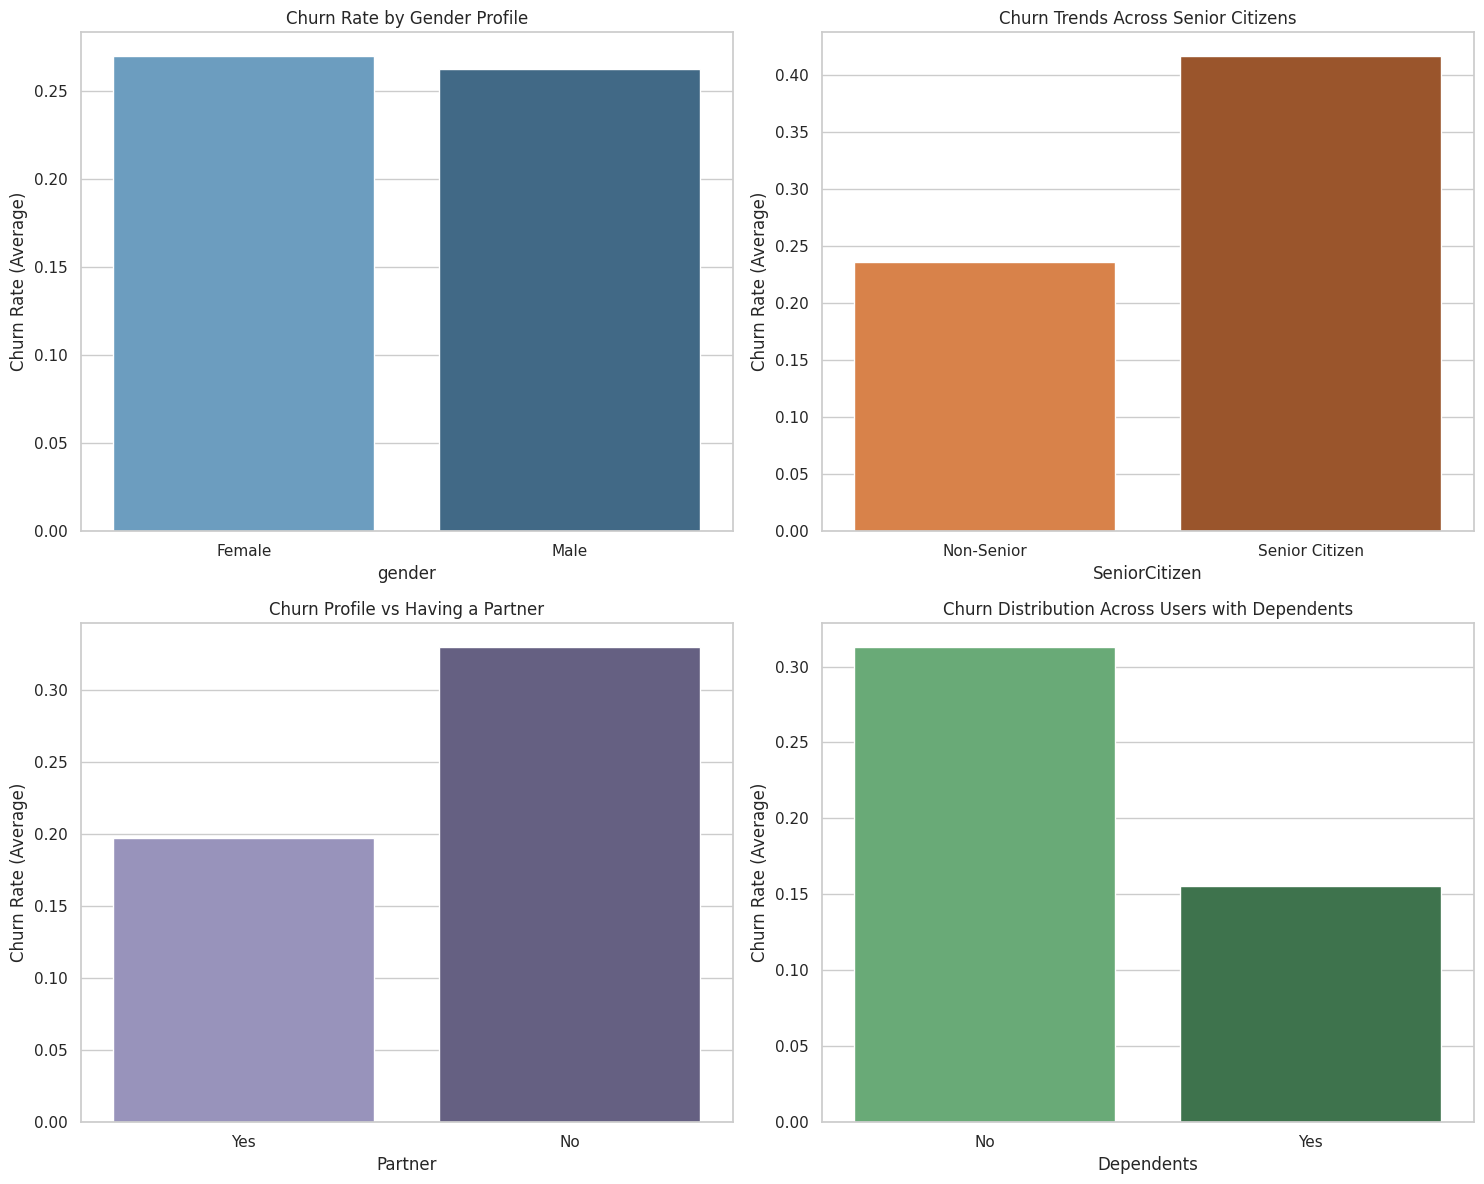

In [16]:
# Set up a 2x2 grid layout for demographic subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
sns.set_theme(style="whitegrid")

# 1. Gender distribution against churn
sns.barplot(x='gender', y='Churn', data=df, ax=axes[0, 0], errorbar=None, hue='gender', legend=False, palette='Blues_d')
axes[0, 0].set_title('Churn Rate by Gender Profile')
axes[0, 0].set_ylabel('Churn Rate (Average)')

# 2. SeniorCitizen and churn (0 = Younger, 1 = Senior)
sns.barplot(x='SeniorCitizen', y='Churn', data=df, ax=axes[0, 1], errorbar=None, hue='SeniorCitizen', legend=False, palette='Oranges_d')
axes[0, 1].set_title('Churn Trends Across Senior Citizens')
axes[0, 1].set_ylabel('Churn Rate (Average)')
axes[0, 1].set_xticks([0, 1])  # Explicitly sets the tick positions first to avoid UserWarnings
axes[0, 1].set_xticklabels(['Non-Senior', 'Senior Citizen'])

# 3. Partner with churn
sns.barplot(x='Partner', y='Churn', data=df, ax=axes[1, 0], errorbar=None, hue='Partner', legend=False, palette='Purples_d')
axes[1, 0].set_title('Churn Profile vs Having a Partner')
axes[1, 0].set_ylabel('Churn Rate (Average)')

# 4. Dependents with churn
sns.barplot(x='Dependents', y='Churn', data=df, ax=axes[1, 1], errorbar=None, hue='Dependents', legend=False, palette='Greens_d')
axes[1, 1].set_title('Churn Distribution Across Users with Dependents')
axes[1, 1].set_ylabel('Churn Rate (Average)')

plt.tight_layout()
plt.show()


• Gender: The pie chart shows a balanced 50/50 customer split. The bar chart shows almost identical attrition levels, proving gender does not influence customer churn.

• SeniorCitizen: Seniors make up a smaller slice of the customer base (around 5-10%), but their bar chart shows a significantly higher churn rate compared to younger citizens.

• Partner & Dependents: The charts reveal that single clients (no partners/dependents) represent a large portion of the business but suffer from heavily elevated churn ratios compared to established family plans.


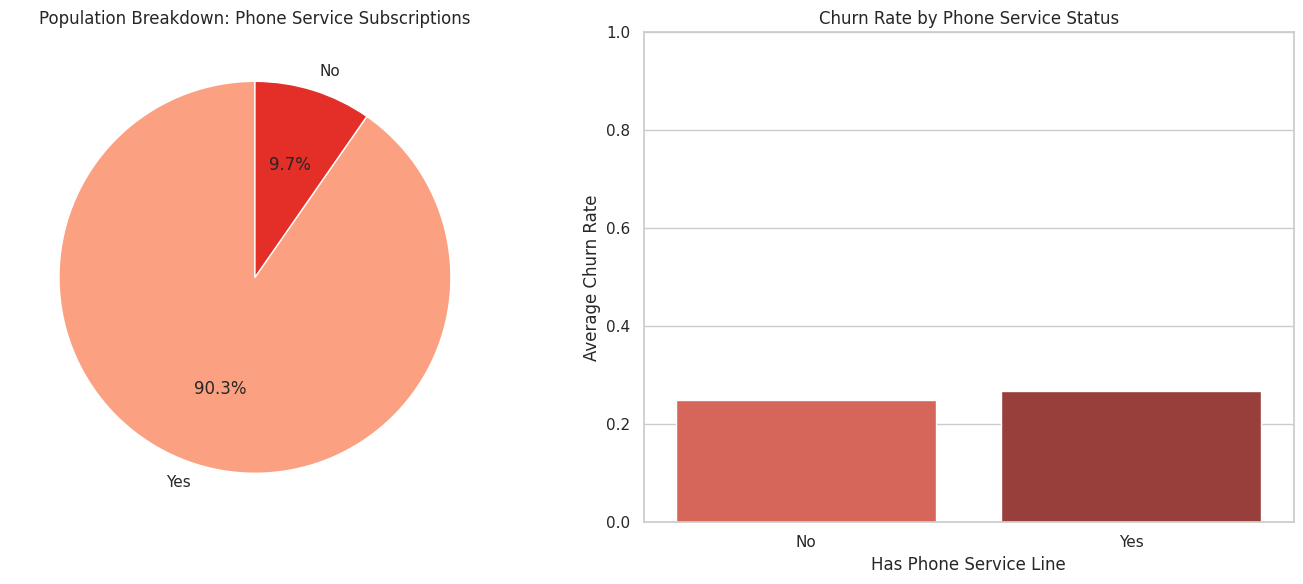

In [17]:
# Create canvas space for Service Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Left Side: Pie Chart for Phone Service Distribution
phone_counts = df['PhoneService'].value_counts()
axes[0].pie(phone_counts, labels=phone_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Reds', 2))
axes[0].set_title('Population Breakdown: Phone Service Subscriptions')

# 2. Right Side: Bar Chart for Churn Rate
sns.barplot(x='PhoneService', y='Churn', data=df, ax=axes[1], errorbar=None, hue='PhoneService', legend=False, palette='Reds_d')
axes[1].set_title('Churn Rate by Phone Service Status')
axes[1].set_xlabel('Has Phone Service Line')
axes[1].set_ylabel('Average Churn Rate')
axes[1].set_ylim(0, 1.0)

plt.tight_layout()
plt.show()


 The vast majority of customers subscribe to a phone line, but the line itself does not impact churn. While the pie chart confirms most users have the service, the bar chart shows equivalent attrition lines between both user groups.

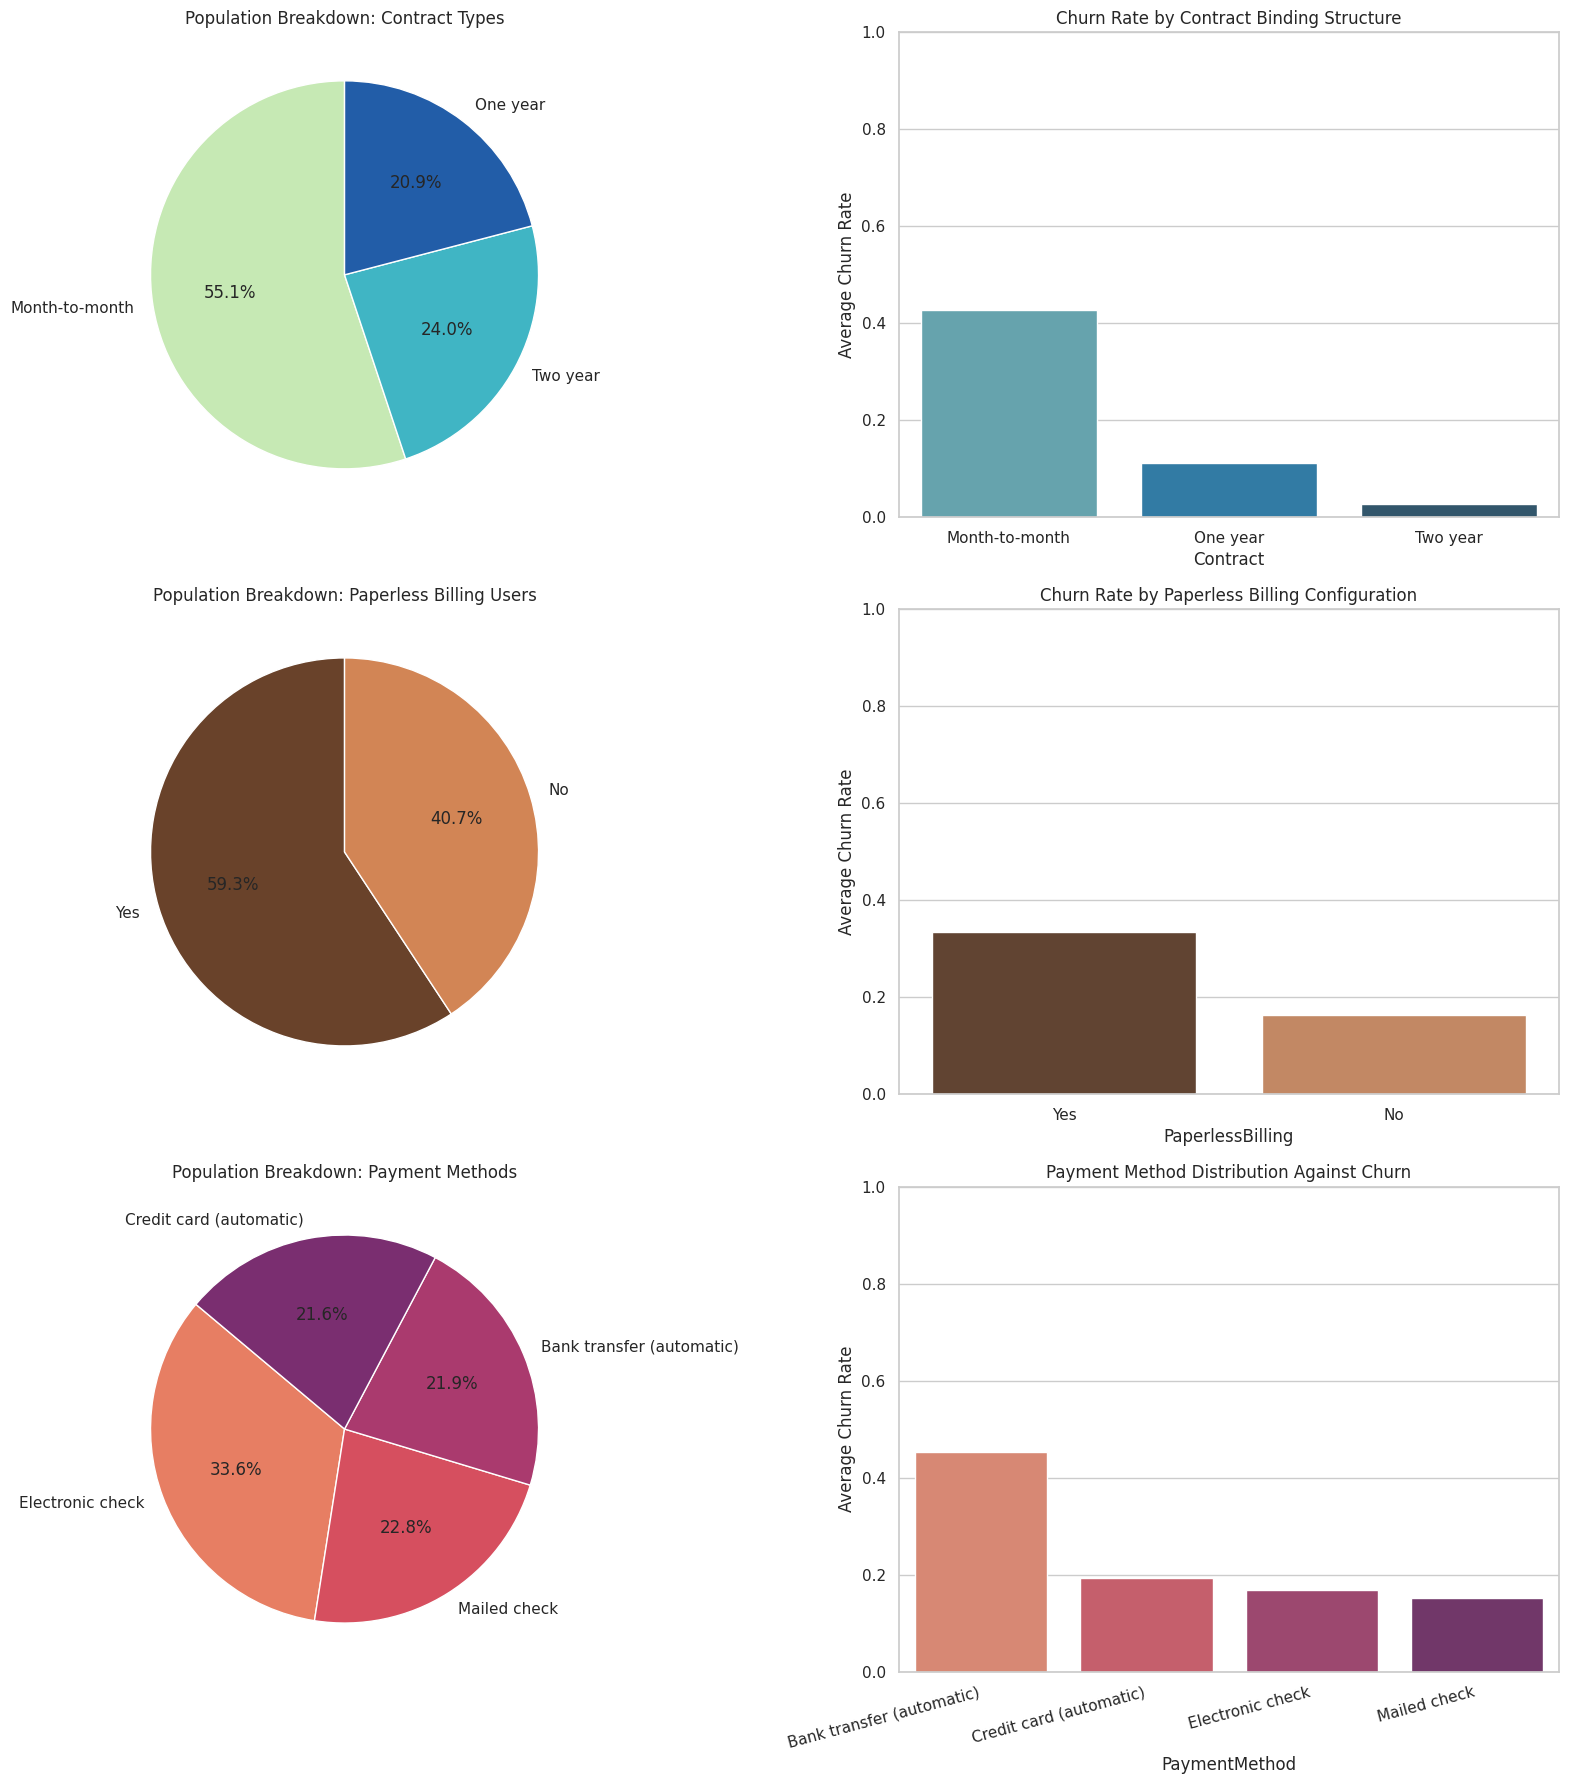

In [18]:
# Set up a grid layout for 3 rows of Pie + Bar chart combinations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# Row 1: Contract Analysis
contract_counts = df['Contract'].value_counts()
axes[0, 0].pie(contract_counts, labels=contract_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('YlGnBu', 3))
axes[0, 0].set_title('Population Breakdown: Contract Types')

sns.barplot(x='Contract', y='Churn', data=df, ax=axes[0, 1], errorbar=None, hue='Contract', legend=False, palette='YlGnBu_d')
axes[0, 1].set_title('Churn Rate by Contract Binding Structure')
axes[0, 1].set_ylabel('Average Churn Rate')
axes[0, 1].set_ylim(0, 1.0)

# Row 2: Paperless Billing Analysis
paperless_counts = df['PaperlessBilling'].value_counts()
axes[1, 0].pie(paperless_counts, labels=paperless_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('copper', 2))
axes[1, 0].set_title('Population Breakdown: Paperless Billing Users')

sns.barplot(x='PaperlessBilling', y='Churn', data=df, ax=axes[1, 1], errorbar=None, hue='PaperlessBilling', legend=False, palette='copper')
axes[1, 1].set_title('Churn Rate by Paperless Billing Configuration')
axes[1, 1].set_ylabel('Average Churn Rate')
axes[1, 1].set_ylim(0, 1.0)

# Row 3: Payment Method Analysis
payment_counts = df['PaymentMethod'].value_counts()
axes[2, 0].pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('flare', 4))
axes[2, 0].set_title('Population Breakdown: Payment Methods')

sns.barplot(x='PaymentMethod', y='Churn', data=df, ax=axes[2, 1], errorbar=None, hue='PaymentMethod', legend=False, palette='flare')
axes[2, 1].set_title('Payment Method Distribution Against Churn')
axes[2, 1].set_ylabel('Average Churn Rate')
axes[2, 1].set_ylim(0, 1.0)

payment_categories = sorted(df['PaymentMethod'].unique())
axes[2, 1].set_xticks(range(len(payment_categories)))
axes[2, 1].set_xticklabels(payment_categories, rotation=15, ha='right')

plt.tight_layout()
plt.show()


• Contract Structure: The pie chart shows Month-to-month plans are very popular. However, the bar chart shows these short-term agreements suffer from an exceptionally high churn risk compared to highly stable 1-year and 2-year contracts.
• Paperless Billing: Digital invoicing is widely adopted, but it correlates with higher overall account turnover rates.
• Payment Method: Electronic checks make up a large portion of customer payments, but they show a massive churn spike. This reveals a critical area where automated payment methods like Credit Cards or direct Bank Transfers keep customers much longer.